# Segmentación y clasificación automática de cromosomas con YOLO11s-seg
### Demostración del proceso, fase por fase

Sebastián Felipe Solano Poveda · Nohelia Agudelo Cuervo · Procesamiento Digital de Imágenes 2026-2

Cada celda es una fase del proceso. **Ejecútalas en orden con ▶** (o *Entorno de ejecución → Ejecutar todas*).

| Fase | Qué muestra |
|---|---|
| 0 | Preparación: instala Ultralytics, conecta Drive y carga los modelos entrenados |
| 1 | Datos crudos: una imagen de prueba de cada dataset |
| 2 | Anotaciones de referencia: lo que el modelo debe aprender |
| 3 | Segmentación (modelo **c1**): encontrar y recortar cada cromosoma |
| 4 | Clasificación (modelo **c24 desde c1**): decir cuál es cada cromosoma (1–22, X, Y) |
| 5 | Cromosomas que se cruzan (modelos **c1** y **c1 + lienzos**) |
| 6 | Métricas en el test de AutoKary (75 metafases anotadas a mano), calculadas en vivo |
| 7 | Resumen |

**Requisitos:** *Entorno de ejecución → Cambiar tipo de entorno → GPU*. El cuaderno no entrena nada y **no escribe nada en Drive**: solo lee los datos y los pesos ya entrenados.

## Fase 0 · Preparación
**Qué hace:** instala Ultralytics (la librería de YOLO), conecta Google Drive y carga los modelos ya entrenados. También elige las imágenes de prueba que se usarán en todas las fases.

**Qué observar:** en la tercera celda debe aparecer ✔ junto a cada modelo. Si alguno sale con ✘, revisa la ruta `RUNS_DIR` en la configuración.

En la configuración se pueden cambiar las imágenes de ejemplo: se escribe el nombre del archivo sin extensión. Si el nombre no existe, se elige una imagen al azar.

In [1]:
#@title Configuración { display-mode: "form" }
DATASET_DIR = '/content/drive/MyDrive/DSP/Dataset'  #@param {type:"string"}
RUNS_DIR = '/content/drive/MyDrive/yolo_runs'  #@param {type:"string"}
EJEMPLO_AUTOKARY = 'autokary_211029-011C_162_1_345_444_0_558'  #@param {type:"string"}
EJEMPLO_54816 = 't54816_1052123'  #@param {type:"string"}
EJEMPLO_SOLAPAMIENTO = 'overlap_341'  #@param {type:"string"}
SEED = 0  #@param {type:"integer"}

UNIFIED = f'{DATASET_DIR}/unified_yolo'          # chromosome1/ y chromosome24/ en formato YOLO
SEG_LABELS_ZIP = f'{DATASET_DIR}/seg_labels.zip'  # polígonos dibujados a mano (AutoKary, solapamientos)
SEG_LABELS_SAM = f'{DATASET_DIR}/seg_labels_sam'  # polígonos de SAM (54816)
CANVAS_ZIP = f'{DATASET_DIR}/overlap_canvases.zip'
WORK = '/content/demo'                            # copia local de trabajo (no se toca Drive)
IMGSZ = 1024
CONF = 0.25
RUNS = {  # nombre corto -> carpeta del entrenamiento en RUNS_DIR
    'c1': 'chromosome1_yolo11s-seg_1024',
    'c24 desde c1': 'chromosome24_yolo11s-seg_1024_desde_c1',
    'c1 + lienzos': 'chromosome1_yolo11s-seg_1024_ft_lienzos',
    'c24 desde COCO': 'chromosome24_yolo11s-seg_1024',
}
print('Configuración lista.')

Configuración lista.


In [2]:
#@title Instalar Ultralytics { display-mode: "form" }
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || echo "Sin GPU"
%pip install -q ultralytics==8.4.192

Tesla T4, 15360 MiB


In [3]:
#@title Conectar Drive, cargar modelos y funciones { display-mode: "form" }
from google.colab import drive

drive.mount('/content/drive')

import csv, glob, os, random, shutil, time, zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Patch
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO

if not torch.cuda.is_available():
    print('AVISO: no hay GPU. Funciona, pero la fase 6 tardará mucho. '
          'Entorno de ejecución → Cambiar tipo de entorno → GPU.')
for path in (UNIFIED, SEG_LABELS_ZIP, RUNS_DIR):
    if not os.path.exists(path):
        raise FileNotFoundError(f'No encuentro {path}. Revisa las rutas de la configuración.')

# --- Polígonos de referencia y lienzos de test: se copian una vez al disco local ---------------------------------
os.makedirs(WORK, exist_ok=True)
if not os.path.isdir(f'{WORK}/seg_labels'):
    with zipfile.ZipFile(SEG_LABELS_ZIP) as z:
        z.extractall(WORK)
if os.path.isfile(CANVAS_ZIP) and not os.path.isdir(f'{WORK}/overlap_canvases'):
    with zipfile.ZipFile(CANVAS_ZIP) as z:  # solo el test y la tabla de posiciones
        z.extractall(WORK, [m for m in z.namelist() if '/test/' in m or m.endswith('placements.csv')])

# --- Modelos entrenados ---------------------------------------------------------------------------------------------
MODELS = {}
for label, run in RUNS.items():
    w = f'{RUNS_DIR}/{run}/weights/best.pt'
    if os.path.exists(w):
        MODELS[label] = YOLO(w)
        print(f'✔ {label:15s} {w}')
    else:
        print(f'✘ {label:15s} no encontrado ({w})')
for needed in ('c1', 'c24 desde c1'):
    if needed not in MODELS:
        raise FileNotFoundError(f'Falta el modelo {needed}: revisa RUNS_DIR.')
NAMES24 = [MODELS['c24 desde c1'].names[i] for i in range(len(MODELS['c24 desde c1'].names))]

# --- Estilo de las figuras ------------------------------------------------------------------------------------------
INK, INK2, MUTED, GRID = '#1f1f1d', '#52514e', '#8a8984', '#e7e6e2'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ERROR = '#d03b3b'
PAIR = [SERIES[0], SERIES[1]]
CROSS, EXTRA = SERIES[2], SERIES[6]
MODEL_COLOR = {'c1': SERIES[0], 'c24 desde COCO': SERIES[1], 'c24 desde c1': SERIES[2], 'c1 + lienzos': SERIES[3]}
DENVER = {'A': ['1', '2', '3'], 'B': ['4', '5'], 'C': ['6', '7', '8', '9', '10', '11', '12', 'X'],
          'D': ['13', '14', '15'], 'E': ['16', '17', '18'], 'F': ['19', '20'], 'G': ['21', '22', 'Y']}
GROUP_OF = {n: g for g, ns in DENVER.items() for n in ns}
GROUP_COLOR = {g: SERIES[i] for i, g in enumerate(DENVER)}
HALO = [pe.withStroke(linewidth=1.8, foreground=INK)]
mpl.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.size': 11, 'text.color': INK,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': INK2, 'ytick.color': INK2, 'legend.frameon': False,
                     'figure.titlesize': 15, 'figure.titleweight': 'bold'})


# --- Archivos ---------------------------------------------------------------------------------------------------------
def stem_of(p):
    return os.path.splitext(os.path.basename(p))[0]


def test_images(variant, prefix):
    folder = f'{UNIFIED}/{variant}/images/test'
    return sorted(os.path.join(folder, f) for f in os.listdir(folder)
                  if f.startswith(prefix) and f.lower().endswith(('.jpg', '.jpeg', '.png')))


def pick(paths, name):
    hit = [p for p in paths if stem_of(p) == name]
    if name and not hit:
        print(f'(no encontré {name}; uso una imagen al azar)')
    return hit[0] if hit else random.Random(SEED).choice(paths)


def gt_label_path(variant, stem):
    """Polígonos dibujados a mano si existen; si no, los de SAM."""
    exact = f'{WORK}/seg_labels/{variant}/test/{stem}.txt'
    return exact if os.path.exists(exact) else f'{SEG_LABELS_SAM}/{variant}/test/{stem}.txt'


def load_rgb(path):
    return np.asarray(PILImage.open(path).convert('RGB'))


# --- Máscaras ---------------------------------------------------------------------------------------------------------
def read_polygons(label_path, W, H):
    out = []
    with open(label_path) as fh:
        for line in fh:
            v = line.split()
            if v:
                out.append((int(v[0]), np.array(v[1:], float).reshape(-1, 2) * [W, H]))
    return out


def polygon_mask(p, W, H):
    m = PILImage.new('1', (W, H), 0)
    ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
    return np.asarray(m)


def gt_instances(label_path, W, H, names=None):
    """[(nombre o None, máscara)] de la anotación de referencia."""
    return [(names[k] if names else None, polygon_mask(p, W, H)) for k, p in read_polygons(label_path, W, H)]


def predict_instances(model, path, conf=CONF):
    """[(nombre, máscara)] de la predicción, una máscara por cromosoma."""
    r = model.predict(path, imgsz=IMGSZ, conf=conf, agnostic_nms=True, retina_masks=True, verbose=False)[0]
    if r.masks is None:
        return []
    H, W = r.orig_shape
    masks = [m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
             for m in r.masks.data.cpu().numpy() > 0.5]
    return [(model.names[int(c)], m) for c, m in zip(r.boxes.cls.tolist(), masks) if m.any()]


def mask_box(m):
    ys, xs = np.flatnonzero(m.any(1)), np.flatnonzero(m.any(0))
    return (xs[0], ys[0], xs[-1] + 1, ys[-1] + 1) if len(xs) else (0, 0, 0, 0)


def boxes_touch(a, b):
    return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]


def union_box(*boxes):
    boxes = [b for b in boxes if b[2] > b[0]]
    return min(b[0] for b in boxes), min(b[1] for b in boxes), max(b[2] for b in boxes), max(b[3] for b in boxes)


def mask_iou(a, b):
    u = (a | b).sum()
    return (a & b).sum() / u if u else 0.0


def iou_in(a, b, box):
    x0, y0, x1, y1 = box
    return mask_iou(a[y0:y1, x0:x1], b[y0:y1, x0:x1])


def match(pred, gt, thr=0.5):
    """Empareja cada predicción con el cromosoma real que más se le parece (IoU >= thr). {i_pred: j_gt}."""
    cand = sorted(((mask_iou(p, g), i, j) for i, (_, p) in enumerate(pred) for j, (_, g) in enumerate(gt)
                   if boxes_touch(mask_box(p), mask_box(g))), reverse=True)
    out, used = {}, set()
    for v, i, j in cand:
        if v < thr:
            break
        if i not in out and j not in used:
            out[i] = j
            used.add(j)
    return out


# --- Dibujo -------------------------------------------------------------------------------------------------------------
def colour_of(name):
    return GROUP_COLOR.get(GROUP_OF.get(str(name)), SERIES[0])


def zoom_box(masks, W, H, margin=25):
    boxes = [mask_box(m) for m in masks if m.any()]
    if not boxes:
        return (0, 0, W, H)
    x0, y0, x1, y1 = union_box(*boxes)
    return max(x0 - margin, 0), max(y0 - margin, 0), min(x1 + margin, W), min(y1 + margin, H)


def draw(ax, img, insts=(), colours=(), labels=None, edges=None, view=None, fontsize=7, title=None, cross=None):
    """Imagen con cada máscara teñida, su contorno fino y una etiqueta pequeña en su centro."""
    out = img.astype(float) / 255
    for (_, m), c in zip(insts, colours):
        out[m] = 0.5 * out[m] + 0.5 * np.array(mpl.colors.to_rgb(c))
    if cross is not None:
        out[cross] = 0.45 * (img[cross] / 255) + 0.55 * np.array(mpl.colors.to_rgb(CROSS))
    ax.imshow(out)
    H, W = img.shape[:2]
    for n, ((_, m), c) in enumerate(zip(insts, colours)):
        x0, y0, x1, y1 = mask_box(m)
        x0, y0, x1, y1 = max(x0 - 1, 0), max(y0 - 1, 0), min(x1 + 1, W), min(y1 + 1, H)
        if x1 - x0 < 2 or y1 - y0 < 2:
            continue
        edge = edges[n] if edges else c
        ax.contour(np.arange(x0, x1), np.arange(y0, y1), m[y0:y1, x0:x1].astype(float), levels=[0.5],
                   colors=[edge], linewidths=1.6 if edge == ERROR else 0.8)
        if labels and labels[n]:
            ys, xs = np.nonzero(m)
            k = np.argmin((xs - xs.mean()) ** 2 + (ys - ys.mean()) ** 2)
            bad = edge == ERROR
            ax.text(xs[k], ys[k], labels[n], fontsize=fontsize, ha='center', va='center', weight='bold',
                    color='white', path_effects=None if bad else HALO,
                    bbox=dict(boxstyle='round,pad=0.15', fc=ERROR, ec='none') if bad else None)
    if view:
        ax.set_xlim(view[0], view[2])
        ax.set_ylim(view[3], view[1])
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, fontsize=11)


def denver_legend(fig, y=0.0, extra=()):
    handles = [Patch(color=GROUP_COLOR[g], label=f'{g}: {", ".join(n)}') for g, n in DENVER.items()] + list(extra)
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y), ncol=5, fontsize=9, handlelength=1.2,
               title='Grupos de Denver (colores de los cromosomas)', title_fontsize=9)


# --- Ejemplos de prueba (los mismos en todas las fases) ---------------------------------------------------------------
EJ = {
    'AutoKary2022': dict(path=pick(test_images('chromosome24', 'autokary_'), EJEMPLO_AUTOKARY), variant='chromosome24',
                         nota='metafase completa · contornos dibujados a mano'),
    '54816': dict(path=pick(test_images('chromosome24', 't54816'), EJEMPLO_54816), variant='chromosome24',
                  nota='metafase completa · contornos generados con SAM'),
    'Solapamientos': dict(path=pick(test_images('chromosome1', 'overlap_'), EJEMPLO_SOLAPAMIENTO), variant='chromosome1',
                          nota='recorte con dos cromosomas cruzados · sin clase'),
}
for name, e in EJ.items():
    e['img'] = load_rgb(e['path'])
    H, W = e['img'].shape[:2]
    names = NAMES24 if e['variant'] == 'chromosome24' else None
    e['gt'] = gt_instances(gt_label_path(e['variant'], stem_of(e['path'])), W, H, names)
print('\nListo. Ejemplos:', ', '.join(f'{k} = {stem_of(e["path"])}' for k, e in EJ.items()))

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✔ c1              /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024/weights/best.pt
✔ c24 desde c1    /content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1/weights/best.pt
✔ c1 + lienzos    /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos/weights/best.pt
✔ c24 desde COCO  /content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024/weights/best.pt

Listo. Ejemplos: AutoKary2022 = autokary_211029-011C_162_1_345_444_0_558, 54816 = t54816_1052123, Solapamientos = overlap_341


## Fase 1 · Datos crudos
**Qué hace:** muestra una imagen de prueba de cada una de las tres bases de datos, tal como llegan, antes de cualquier procesamiento.

**Qué observar:**
- **AutoKary2022** y **54816** son metafases completas: la célula entera con sus 46 cromosomas.
- **Solapamientos** son recortes pequeños con solo dos cromosomas cruzados.
- La tabla resume qué aporta cada base y cuántas imágenes de prueba tiene.

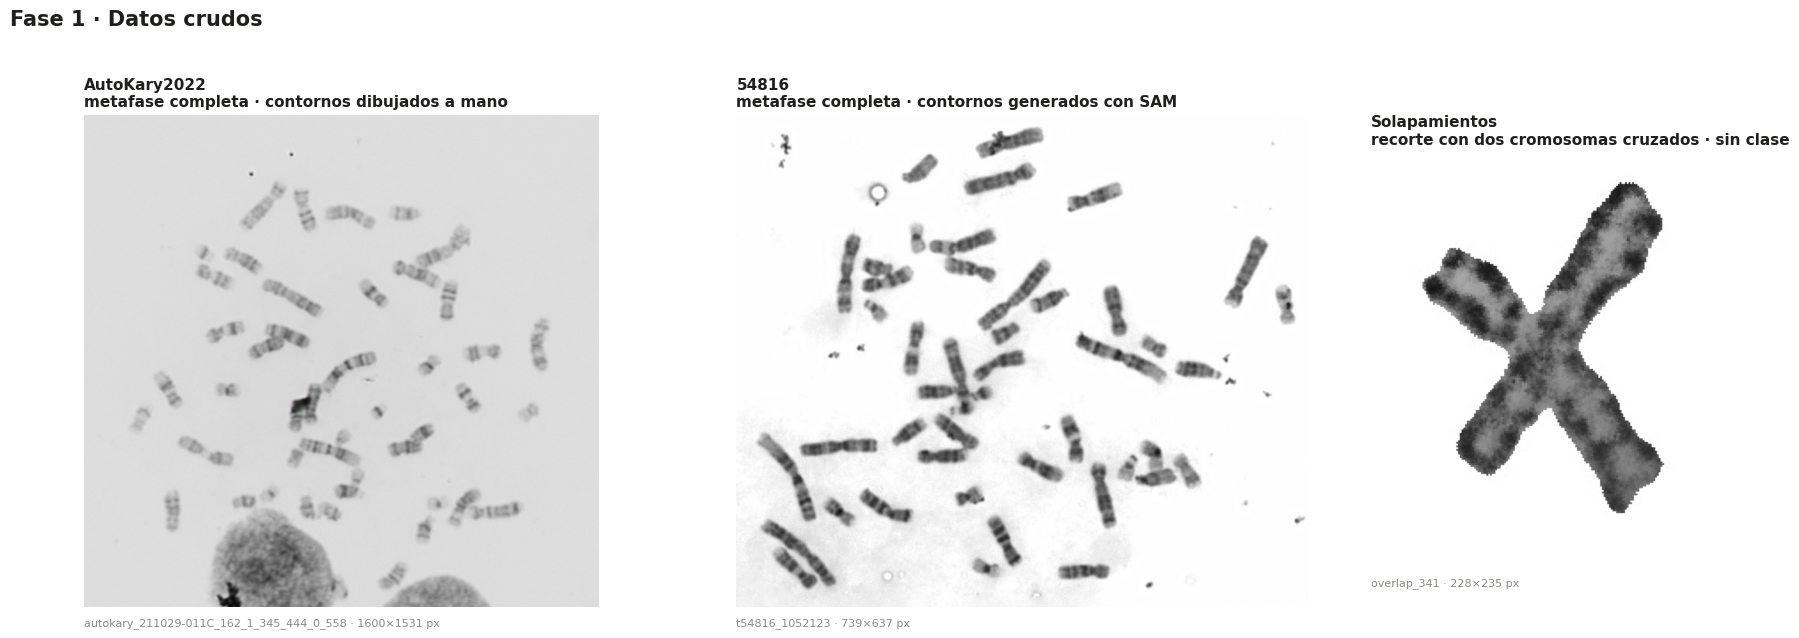

Dataset,Contenido,Clases,Contornos,Imágenes de test
AutoKary2022,Metafases completas,"24 (1–22, X, Y)",Dibujados a mano,75
54816,Metafases completas,"24 (1–22, X, Y)",Cajas → SAM,1250
Solapamientos,Recortes de 2 cromosomas cruzados,Sin clase,Dibujados a mano,73


In [4]:
#@title Ver una imagen de prueba de cada dataset { display-mode: "form" }
counts = {name: len(test_images(e['variant'], {'AutoKary2022': 'autokary_', '54816': 't54816',
                                                 'Solapamientos': 'overlap_'}[name])) for name, e in EJ.items()}
fig, axes = plt.subplots(1, 3, figsize=(18, 6.3), gridspec_kw=dict(width_ratios=[1.15, 1.15, 0.7]))
for ax, (name, e) in zip(axes, EJ.items()):
    H, W = e['img'].shape[:2]
    draw(ax, e['img'], title=f'{name}\n{e["nota"]}')
    ax.text(0, -0.02, f'{stem_of(e["path"])} · {W}×{H} px', transform=ax.transAxes, fontsize=8, color=MUTED, va='top')
fig.suptitle('Fase 1 · Datos crudos', x=0.01, ha='left')
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

display(pd.DataFrame([
    {'Dataset': 'AutoKary2022', 'Contenido': 'Metafases completas', 'Clases': '24 (1–22, X, Y)',
     'Contornos': 'Dibujados a mano', 'Imágenes de test': counts['AutoKary2022']},
    {'Dataset': '54816', 'Contenido': 'Metafases completas', 'Clases': '24 (1–22, X, Y)',
     'Contornos': 'Cajas → SAM', 'Imágenes de test': counts['54816']},
    {'Dataset': 'Solapamientos', 'Contenido': 'Recortes de 2 cromosomas cruzados', 'Clases': 'Sin clase',
     'Contornos': 'Dibujados a mano', 'Imágenes de test': counts['Solapamientos']},
]).style.hide(axis='index'))

## Fase 2 · Anotaciones de referencia
**Qué hace:** dibuja sobre las mismas imágenes los contornos "correctos", es decir, lo que el modelo debe aprender a reproducir.

**Qué observar:**
- En las metafases, cada cromosoma tiene su número y un color según su **grupo de Denver** (A–G), la clasificación que usan los genetistas por tamaño y forma.
- En AutoKary los contornos los dibujó una persona; en 54816 los generó **SAM** a partir de rectángulos.
- En el recorte de solapamientos, la zona **verde** es donde un cromosoma pasa por encima del otro.

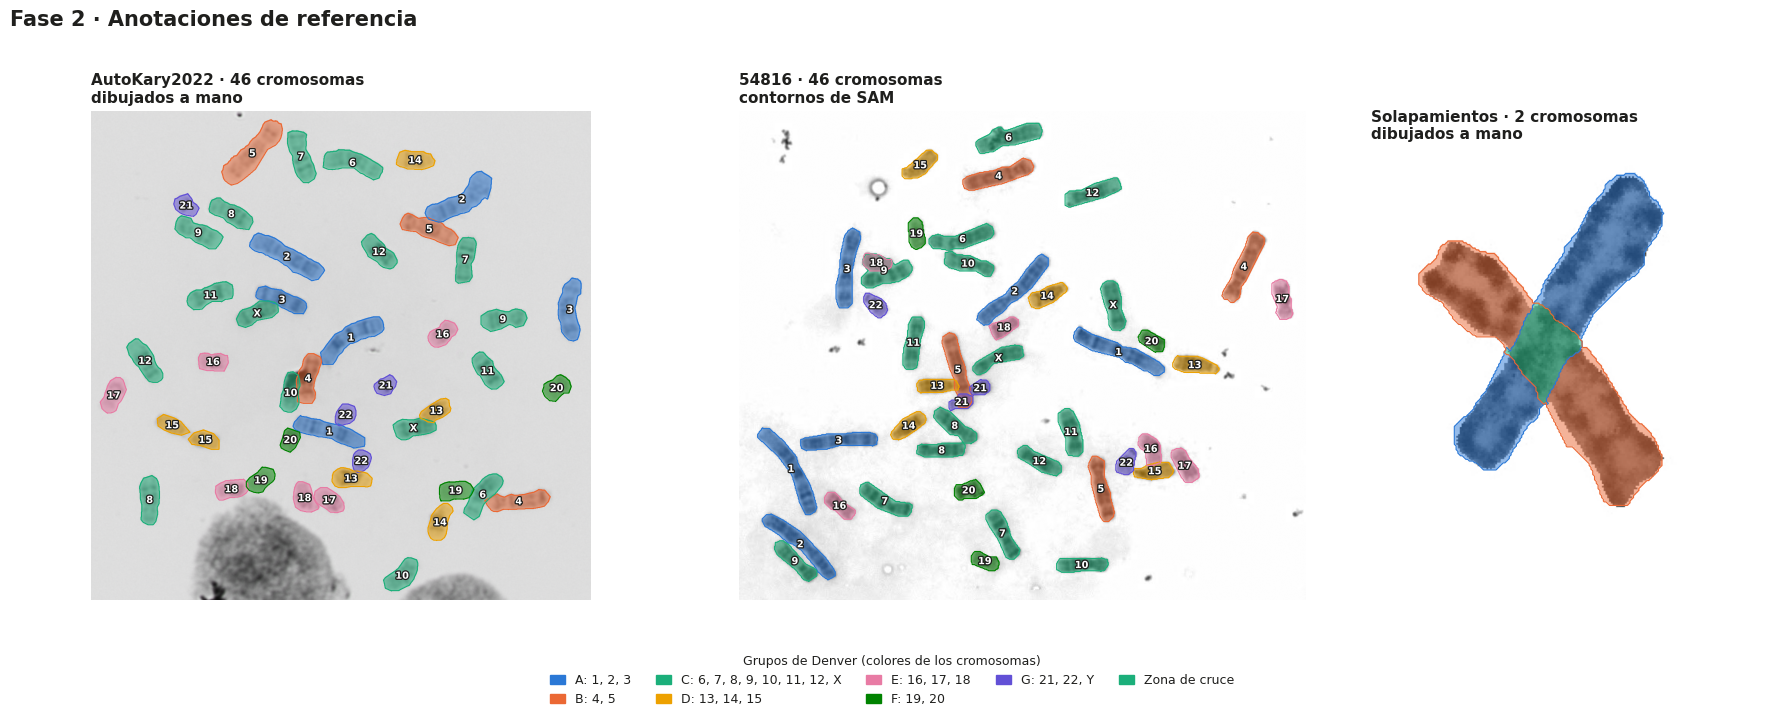

In [5]:
#@title Ver las anotaciones de referencia { display-mode: "form" }
fig, axes = plt.subplots(1, 3, figsize=(18, 6.6), gridspec_kw=dict(width_ratios=[1.15, 1.15, 0.7]))
for ax, (name, e) in zip(axes, EJ.items()):
    H, W = e['img'].shape[:2]
    if e['variant'] == 'chromosome24':
        colours, labels, view = [colour_of(n) for n, _ in e['gt']], [n for n, _ in e['gt']], zoom_box([m for _, m in e['gt']], W, H)
    else:
        colours, labels, view = [PAIR[k % 2] for k in range(len(e['gt']))], None, None
    cross = np.sum([m for _, m in e['gt']], 0) >= 2 if e['variant'] == 'chromosome1' else None
    draw(ax, e['img'], e['gt'], colours, labels, view=view, cross=cross,
         title=f'{name} · {len(e["gt"])} cromosomas\n{"dibujados a mano" if "SAM" not in e["nota"] else "contornos de SAM"}')
fig.suptitle('Fase 2 · Anotaciones de referencia', x=0.01, ha='left')
denver_legend(fig, y=0.02, extra=[Patch(color=CROSS, label='Zona de cruce')])
plt.tight_layout(rect=(0, 0.06, 1, 0.93))
plt.show()

## Fase 3 · Segmentación (modelo c1)
**Qué hace:** el modelo **c1** busca cada cromosoma y dibuja su contorno, sin decir cuál es: para él todos son "cromosoma". Es la **primera etapa** del método. Se entrenó con las tres bases.

**Qué observar:** cuántos cromosomas encuentra y cuántos coinciden con la referencia. Se cuenta como acierto si el contorno coincide al menos en un 50 % (IoU ≥ 0.5).

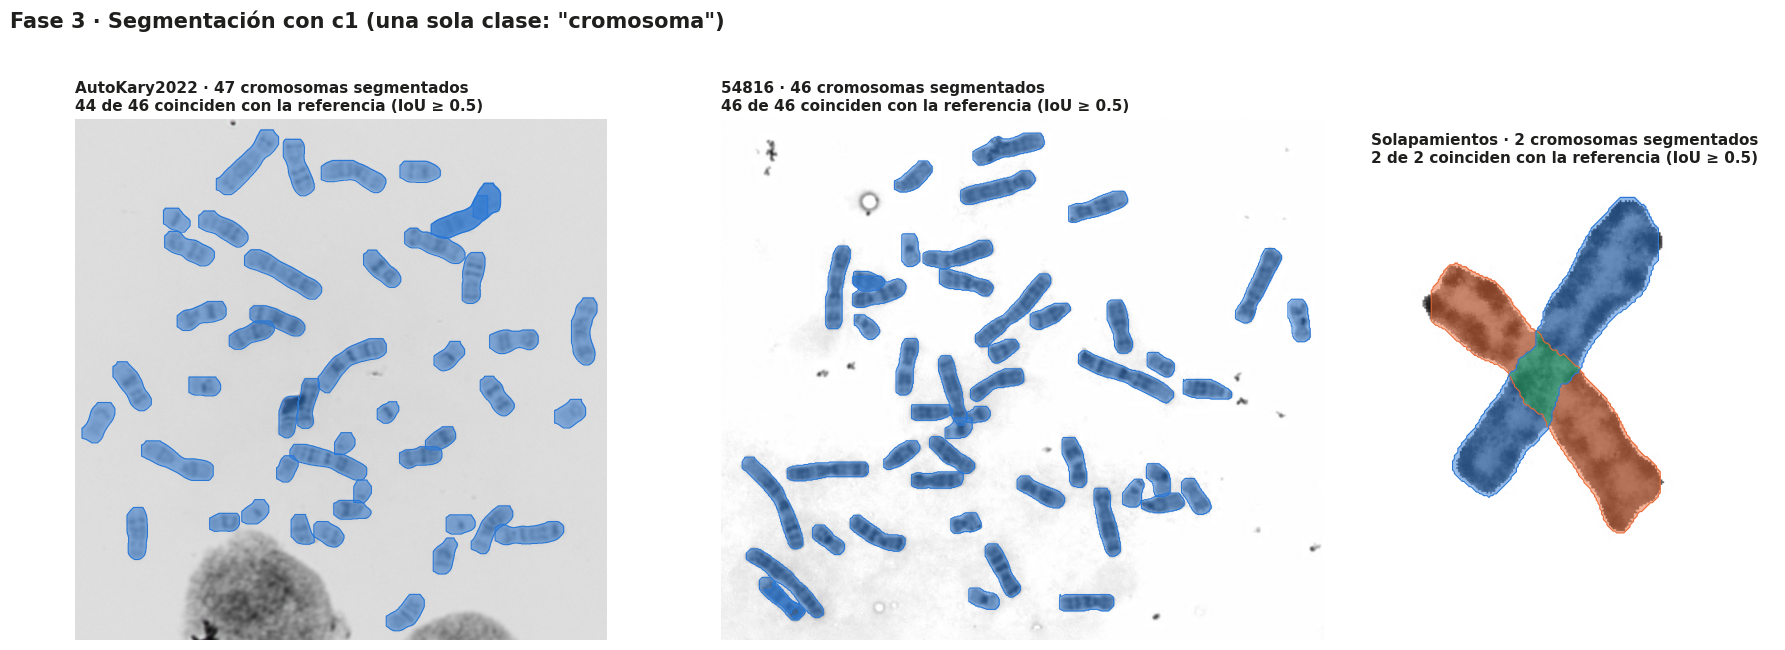

Tiempo de las tres predicciones: 16.5 s


In [6]:
#@title Segmentar las imágenes de prueba con c1 { display-mode: "form" }
t0 = time.time()
SEGM = {name: predict_instances(MODELS['c1'], e['path']) for name, e in EJ.items()}
fig, axes = plt.subplots(1, 3, figsize=(18, 6.6), gridspec_kw=dict(width_ratios=[1.15, 1.15, 0.7]))
for ax, (name, e) in zip(axes, EJ.items()):
    H, W = e['img'].shape[:2]
    pred = SEGM[name]
    found = len(set(match(pred, e['gt']).values()))
    if e['variant'] == 'chromosome24':
        colours, view, cross = [SERIES[0]] * len(pred), zoom_box([m for _, m in e['gt']], W, H), None
    else:
        owner = {i: j for i, j in match(pred, e['gt']).items()}
        colours, view = [PAIR[owner[i] % 2] if i in owner else EXTRA for i in range(len(pred))], None
        cross = np.sum([m for _, m in pred], 0) >= 2 if len(pred) >= 2 else None
    draw(ax, e['img'], pred, colours, view=view, cross=cross,
         title=f'{name} · {len(pred)} cromosomas segmentados\n{found} de {len(e["gt"])} coinciden con la referencia (IoU ≥ 0.5)')
fig.suptitle('Fase 3 · Segmentación con c1 (una sola clase: "cromosoma")', x=0.01, ha='left')
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
print(f'Tiempo de las tres predicciones: {time.time() - t0:.1f} s')

## Fase 4 · Clasificación (modelo c24 desde c1)
**Qué hace:** el modelo **c24 desde c1** parte de c1, que ya sabe segmentar, y además dice cuál es cada cromosoma (1–22, X o Y). Es la **segunda etapa** del método.

**Qué observar:**
- A la izquierda está la referencia; a la derecha, la predicción.
- Los errores aparecen en **rojo**: "7≠10" significa que el modelo dijo 7 y era 10; "7?" significa que marcó un cromosoma donde no había ninguno.
- Los errores suelen ocurrir entre cromosomas de tamaño y forma parecidos.

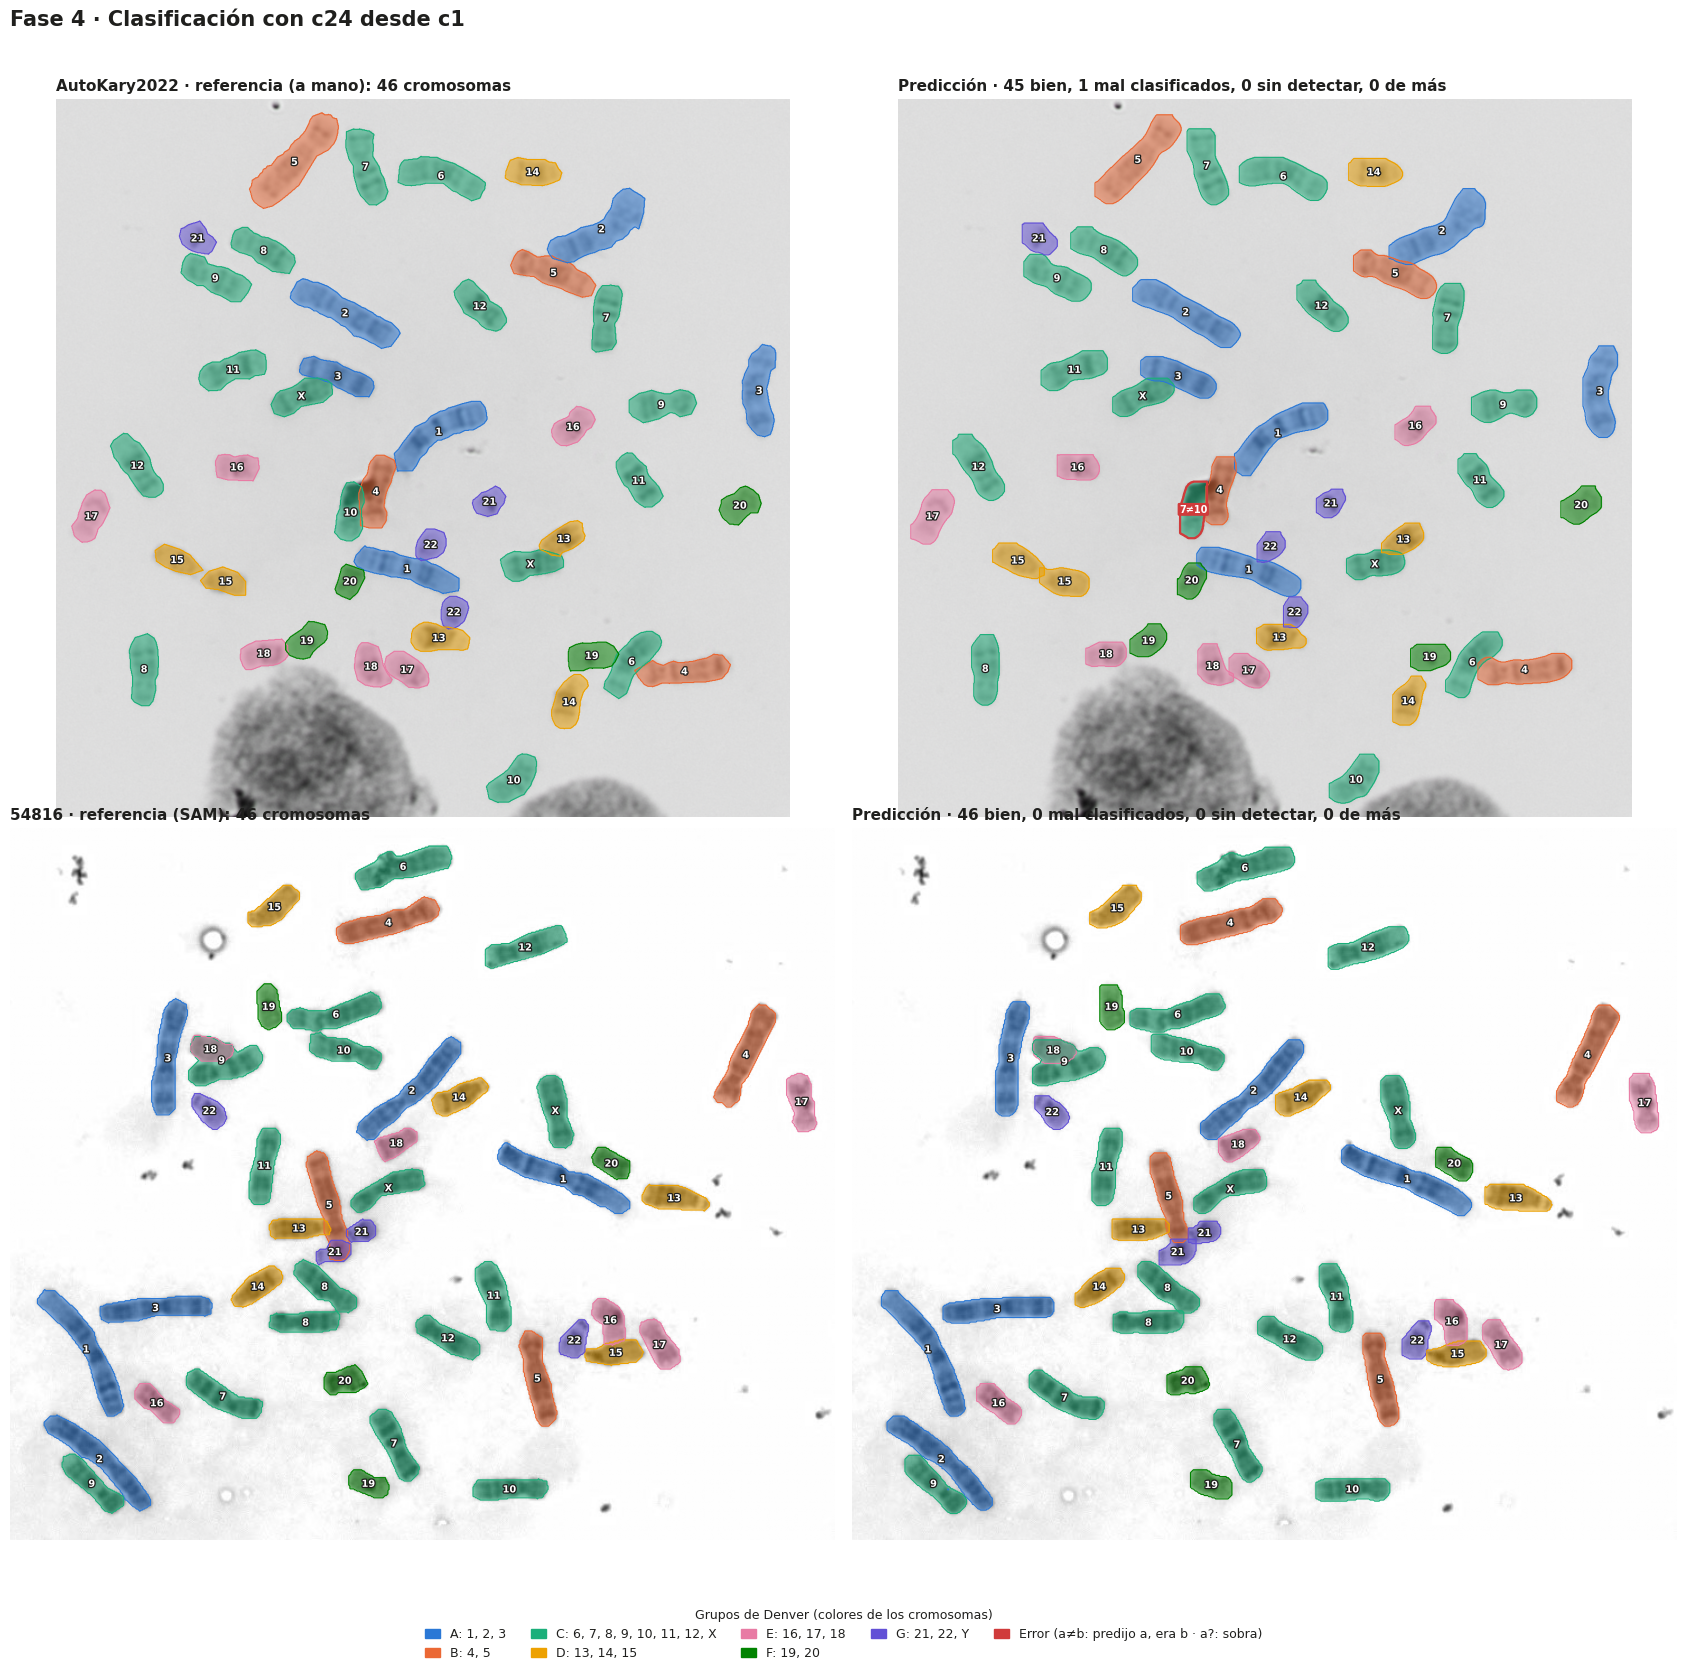

AutoKary2022: 45 de 46 cromosomas con la clase correcta (98%)
54816: 46 de 46 cromosomas con la clase correcta (100%)


In [7]:
#@title Clasificar los cromosomas de las metafases { display-mode: "form" }
CLAS = {}
metaphases = {k: e for k, e in EJ.items() if e['variant'] == 'chromosome24'}
fig, axes = plt.subplots(len(metaphases), 2, figsize=(17, 8.2 * len(metaphases)), squeeze=False)
for row, (name, e) in enumerate(metaphases.items()):
    H, W = e['img'].shape[:2]
    gt = e['gt']
    pred = predict_instances(MODELS['c24 desde c1'], e['path'])
    m = match(pred, gt)
    ok = sum(pred[i][0] == gt[j][0] for i, j in m.items())
    wrong, missed, extra = len(m) - ok, len(gt) - len(set(m.values())), len(pred) - len(m)
    CLAS[name] = dict(ok=ok, wrong=wrong, missed=missed, extra=extra, total=len(gt))
    view = zoom_box([mm for _, mm in gt + pred], W, H)
    matched = set(m.values())
    draw(axes[row, 0], e['img'], gt, [colour_of(n) for n, _ in gt], [n for n, _ in gt],
         edges=[colour_of(n) if j in matched else ERROR for j, (n, _) in enumerate(gt)], view=view,
         title=f'{name} · referencia ({"a mano" if name == "AutoKary2022" else "SAM"}): {len(gt)} cromosomas')
    labels, edges = [], []
    for i, (n, _) in enumerate(pred):
        j = m.get(i)
        good = j is not None and gt[j][0] == n
        labels.append(n if good else f'{n}≠{gt[j][0]}' if j is not None else f'{n}?')
        edges.append(colour_of(n) if good else ERROR)
    draw(axes[row, 1], e['img'], pred, [colour_of(n) for n, _ in pred], labels, edges=edges, view=view,
         title=f'Predicción · {ok} bien, {wrong} mal clasificados, {missed} sin detectar, {extra} de más')
fig.suptitle('Fase 4 · Clasificación con c24 desde c1', x=0.01, ha='left')
denver_legend(fig, y=0.012, extra=[Patch(color=ERROR, label='Error (a≠b: predijo a, era b · a?: sobra)')])
plt.tight_layout(rect=(0, 0.035, 1, 0.97))
plt.show()
for name, r in CLAS.items():
    print(f'{name}: {r["ok"]} de {r["total"]} cromosomas con la clase correcta ({r["ok"] / max(r["total"], 1):.0%})')

## Fase 5 · Cromosomas que se cruzan
**Qué hace:** toma recortes de dos cromosomas cruzados y los pone **a su tamaño real** dentro de un lienzo de 1024 px, como se verían en una metafase. Compara dos modelos:
- **c1**, que se entrenó con estos recortes agrandados;
- **c1 + lienzos**, el mismo modelo con un ajuste fino en lienzos sintéticos, para que aprenda a verlos a tamaño real.

**Qué observar:**
- Cada columna es un recorte distinto. Azul y naranja son los dos cromosomas; **verde** es la zona donde se cruzan.
- Debajo de cada predicción aparece el **IoU** de cada cromosoma (de 0 a 1; más es mejor) y el de la zona de cruce.
- La tabla final resume los **73 recortes de prueba** completos, no solo los que se muestran.

73 recortes evaluados en 31 s


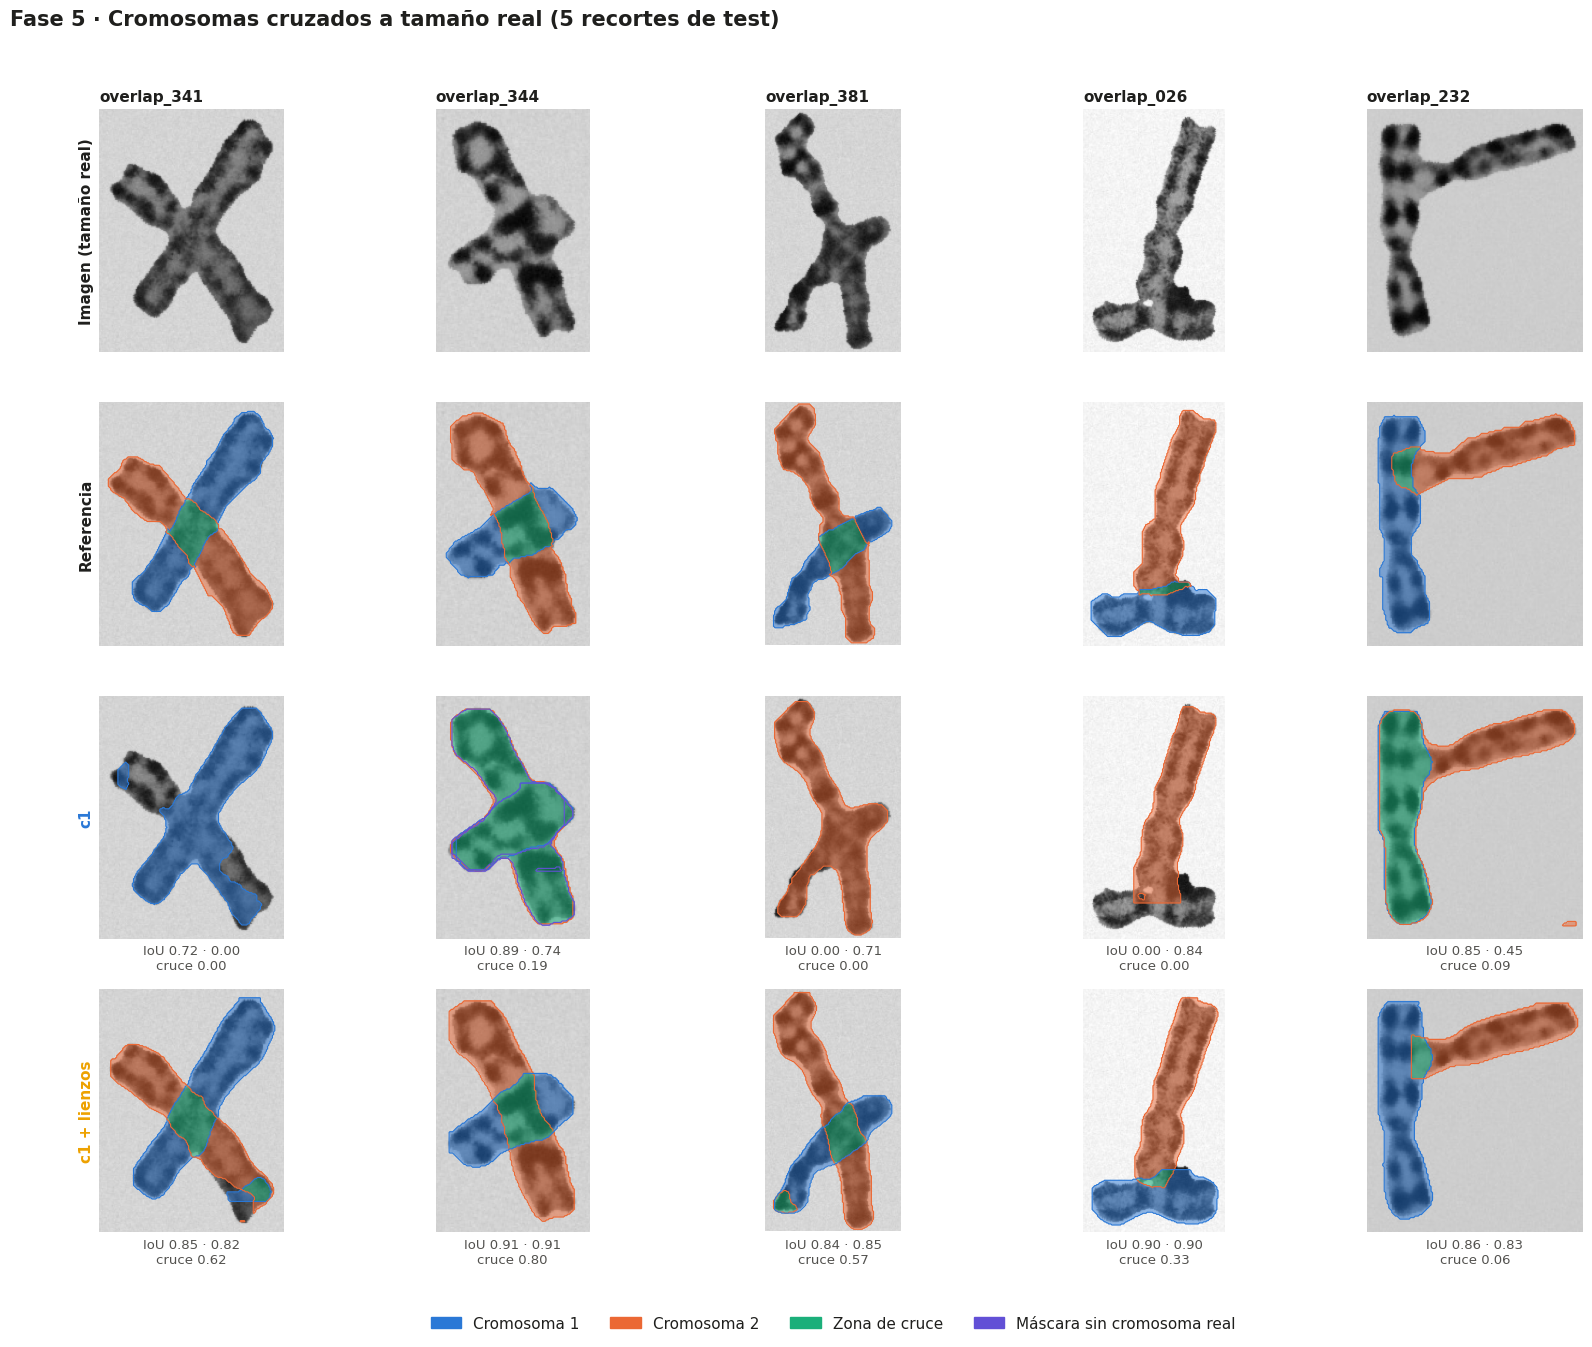

Caso,Recortes,IoU medio por cromosoma,IoU medio del cruce,Recortes con 2 máscaras
c1 · recorte ampliado,73,0.84,0.39,70%
c1 · tamaño real,73,0.39,0.08,33%
c1 + lienzos · tamaño real,73,0.83,0.44,79%


In [8]:
#@title Separar cromosomas cruzados { display-mode: "form" }
N_RECORTES = 5
MIN_CROSS = 0.02  # el IoU del cruce se mide si la zona compartida es al menos el 2 % del cromosoma más pequeño
canvas_dir = f'{WORK}/overlap_canvases'
if not (os.path.isdir(canvas_dir) and 'c1 + lienzos' in MODELS):
    raise RuntimeError('Faltan los lienzos de test o el modelo c1 + lienzos.')


def evaluate_crop(gt, pred):
    # Empareja cada cromosoma real con la máscara que más se le parece y mide el IoU de cada uno y del cruce
    g_m, p_m = [m for _, m in gt], [m for _, m in pred]
    ious = np.array([[mask_iou(g, q) for q in p_m] for g in g_m]).reshape(len(g_m), len(p_m))
    owner = {}
    for v, j, i in sorted(((ious[j, i], j, i) for j in range(len(g_m)) for i in range(len(p_m))), reverse=True):
        if v > 0 and j not in owner and i not in owner.values():
            owner[j] = i
    gt_cross = np.sum(g_m, 0) >= 2
    p_cross = np.sum(p_m, 0) >= 2 if len(p_m) >= 2 else np.zeros_like(gt_cross)
    share = gt_cross.sum() / max(min(g.sum() for g in g_m), 1)
    return dict(chrom=[ious[j, owner[j]] if j in owner else 0.0 for j in range(len(g_m))], owner=owner,
                p_cross=p_cross, cross=mask_iou(gt_cross, p_cross) if share >= MIN_CROSS else None, n=len(p_m))


def predict_regions(model, path, places):
    # Predice el lienzo completo una vez y reparte las máscaras entre sus recortes (la mitad o más dentro)
    masks = predict_instances(model, path)
    out = {}
    for pl in places:
        x0, y0, w, h = (int(pl[k]) for k in ('x0', 'y0', 'w', 'h'))
        out[pl['crop']] = [(n, m[y0:y0 + h, x0:x0 + w]) for n, m in masks
                           if m[y0:y0 + h, x0:x0 + w].any() and m[y0:y0 + h, x0:x0 + w].sum() >= 0.5 * m.sum()]
    return out


t0 = time.time()
with open(f'{canvas_dir}/placements.csv') as fh:
    places = [p for p in csv.DictReader(fh) if p['split'] == 'test']
by_canvas = {}
for pl in places:
    by_canvas.setdefault(pl['canvas'], []).append(pl)
crops = sorted({pl['crop'] for pl in places})
first = stem_of(EJ['Solapamientos']['path'])
others = [c for c in crops if c != first]
shown = ([first] if first in crops else []) + random.Random(SEED).sample(others, min(N_RECORTES, len(others)))
shown = shown[:N_RECORTES]
crop_path = {stem_of(p): p for p in test_images('chromosome1', 'overlap_')}

CASOS = {'c1 · recorte ampliado': [], 'c1 · tamaño real': [], 'c1 + lienzos · tamaño real': []}
SHOW = {}
for canvas, pls in by_canvas.items():
    cpath = f'{canvas_dir}/images/test/{canvas}.jpg'
    preds = {label: predict_regions(MODELS[label], cpath, pls) for label in ('c1', 'c1 + lienzos')}
    full = None
    for pl in pls:
        crop, (x0, y0, w, h) = pl['crop'], (int(pl[k]) for k in ('x0', 'y0', 'w', 'h'))
        gt = gt_instances(gt_label_path('chromosome1', crop), w, h)
        CASOS['c1 · tamaño real'].append(evaluate_crop(gt, preds['c1'][crop]))
        CASOS['c1 + lienzos · tamaño real'].append(evaluate_crop(gt, preds['c1 + lienzos'][crop]))
        if crop in crop_path:  # el mismo recorte, agrandado como en el entrenamiento de c1
            CASOS['c1 · recorte ampliado'].append(evaluate_crop(gt, predict_instances(MODELS['c1'], crop_path[crop])))
        if crop in shown:
            full = load_rgb(cpath) if full is None else full
            SHOW[crop] = dict(img=full[y0:y0 + h, x0:x0 + w], gt=gt, pred={l: preds[l][crop] for l in preds})
print(f'{len(places)} recortes evaluados en {time.time() - t0:.0f} s')

# --- Figura: una columna por recorte -----------------------------------------------------------------------------------
rows = ['Imagen (tamaño real)', 'Referencia', 'c1', 'c1 + lienzos']
cols = [c for c in shown if c in SHOW]
fig, axes = plt.subplots(len(rows), len(cols), figsize=(3.2 * len(cols) + 0.8, 3.35 * len(rows)), squeeze=False)
for col, crop in enumerate(cols):
    d = SHOW[crop]
    img, gt = d['img'], d['gt']
    view = zoom_box([m for _, m in gt], img.shape[1], img.shape[0], margin=8)
    draw(axes[0, col], img, view=view, title=crop)
    draw(axes[1, col], img, gt, [PAIR[k % 2] for k in range(len(gt))], view=view,
         cross=np.sum([m for _, m in gt], 0) >= 2)
    for row, label in ((2, 'c1'), (3, 'c1 + lienzos')):
        pred = d['pred'][label]
        r = evaluate_crop(gt, pred)
        owner = {i: j for j, i in r['owner'].items()}
        draw(axes[row, col], img, pred, [PAIR[owner[i] % 2] if i in owner else EXTRA for i in range(len(pred))],
             view=view, cross=r['p_cross'])
        txt = 'IoU ' + ' · '.join(f'{v:.2f}' for v in r['chrom'])
        txt += f'\ncruce {r["cross"]:.2f}' if r['cross'] is not None else ''
        axes[row, col].set_xlabel(txt, fontsize=9.5, color=INK2)
for ax, label in zip(axes[:, 0], rows):
    ax.set_ylabel(label, fontsize=11, weight='bold', color=MODEL_COLOR.get(label, INK))
fig.legend(handles=[Patch(color=PAIR[0], label='Cromosoma 1'), Patch(color=PAIR[1], label='Cromosoma 2'),
                    Patch(color=CROSS, label='Zona de cruce'), Patch(color=EXTRA, label='Máscara sin cromosoma real')],
           loc='upper center', bbox_to_anchor=(0.5, 0.015), ncol=4)
fig.suptitle(f'Fase 5 · Cromosomas cruzados a tamaño real ({len(cols)} recortes de test)', x=0.01, ha='left')
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.show()

# --- Tabla: los 73 recortes de test --------------------------------------------------------------------------------------
CRUCES = pd.DataFrame([{
    'Caso': caso, 'Recortes': len(rs),
    'IoU medio por cromosoma': np.mean([v for r in rs for v in r['chrom']]),
    'IoU medio del cruce': np.mean([r['cross'] for r in rs if r['cross'] is not None]),
    'Recortes con 2 máscaras': np.mean([r['n'] == 2 for r in rs]),
} for caso, rs in CASOS.items() if rs])
display(CRUCES.style.format({'IoU medio por cromosoma': '{:.2f}', 'IoU medio del cruce': '{:.2f}',
                             'Recortes con 2 máscaras': '{:.0%}'}).hide(axis='index'))

## Fase 6 · Métricas
**Qué hace:** evalúa los modelos en las **75 metafases de prueba de AutoKary**, la única base con contornos dibujados a mano. Se calcula en vivo, así que tarda unos minutos con GPU.

**Las métricas:**
- **mAP50:** ¿encuentra los cromosomas? Cuenta como acierto si el contorno coincide al menos en un 50 %. Va de 0 a 1.
- **mAP50-95:** ¿qué tan exacto es el contorno? Repite la cuenta exigiendo del 50 % al 95 % de coincidencia y promedia.
- **Segmentación:** se calcula sin mirar la clase (todo es "cromosoma"). **Clasificación:** además exige el número correcto. c1 y c1 + lienzos solo tienen segmentación, porque no clasifican.
- **Matriz de confusión:** las filas son el cromosoma real y las columnas lo que predijo el modelo. Lo ideal es que todo quede en la diagonal; lo que queda fuera son las confusiones.

75 metafases de AutoKary listas (23 s). Evaluando...
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3627.8±1045.6 MB/s, size: 2398.2 KB)
val: Scanning /content/demo/autokary_test/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 220.5it/s 0.3s
val: New cache created: /content/demo/autokary_test/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.0it/s 9.7s
                   all         75       3208      0.977      0.985      0.992      0.848      0.975      0.984      0.992      0.763
Speed: 5.6ms preprocess, 31.6ms inference, 0.0ms loss, 4.2ms postprocess per image
  c1 ✔
Ultralytics 8.4.192

Modelo,Segmentación mAP50,Segmentación mAP50-95,Clasificación mAP50,Clasificación mAP50-95
c1,0.992,0.763,—,—
c24 desde COCO,0.993,0.744,0.960,0.717
c24 desde c1,0.993,0.760,0.958,0.731
c1 + lienzos,0.992,0.753,—,—



c24 desde c1 · cromosomas bien clasificados: 93.7%


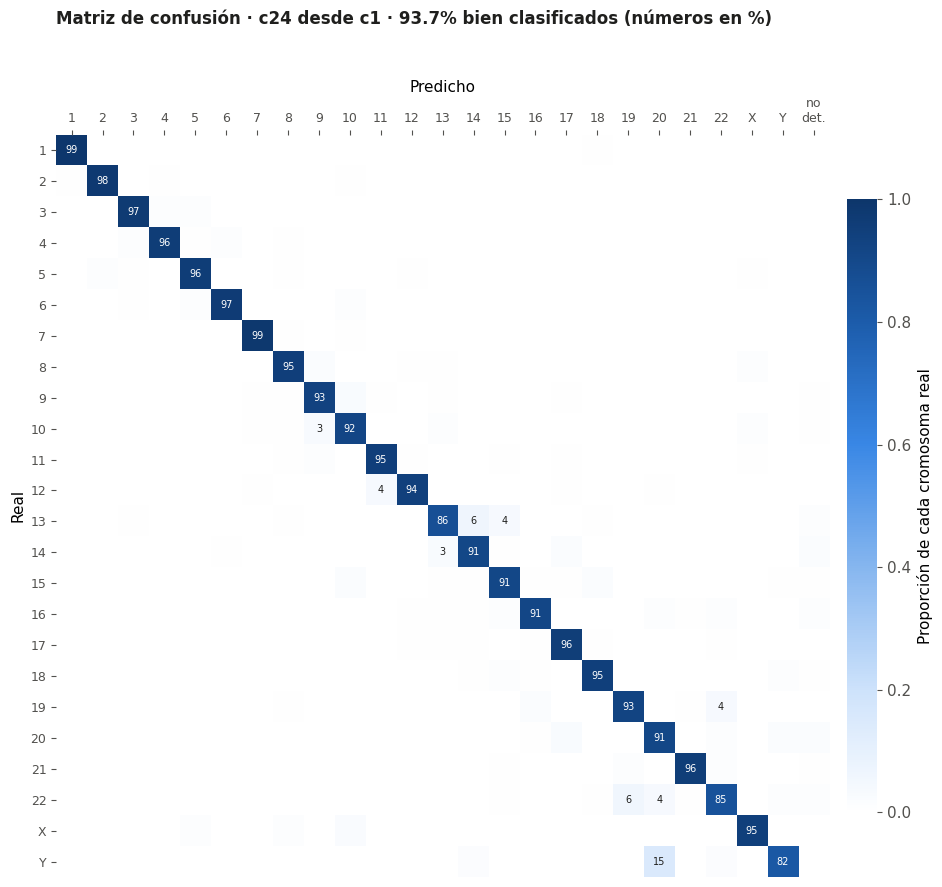

In [9]:
#@title Calcular las métricas en el test de AutoKary { display-mode: "form" }
t0 = time.time()
# Conjunto de test local: las 75 metafases de AutoKary con sus contornos dibujados a mano
AK_DIR = f'{WORK}/autokary_test'
for sub in ('images', 'labels'):
    os.makedirs(f'{AK_DIR}/{sub}/test', exist_ok=True)
AK = test_images('chromosome24', 'autokary_')
for p in AK:
    dst = f'{AK_DIR}/images/test/{os.path.basename(p)}'
    if not os.path.exists(dst):
        shutil.copyfile(p, dst)
    lbl = f'{AK_DIR}/labels/test/{stem_of(p)}.txt'
    if not os.path.exists(lbl):
        open(lbl, 'w').write(open(gt_label_path('chromosome24', stem_of(p))).read())
AK_YAML = f'{AK_DIR}/data.yaml'
with open(AK_YAML, 'w') as fh:
    fh.write(f'path: {AK_DIR}\ntrain: images/test\nval: images/test\ntest: images/test\nnc: {len(NAMES24)}\nnames:\n'
             + ''.join(f"  {i}: '{n}'\n" for i, n in enumerate(NAMES24)))
print(f'{len(AK)} metafases de AutoKary listas ({time.time() - t0:.0f} s). Evaluando...')

VAL = dict(data=AK_YAML, split='test', imgsz=IMGSZ, batch=8, plots=False, verbose=False, project=f'{WORK}/val', exist_ok=True)
METRICAS = []
for label in [l for l in ('c1', 'c24 desde COCO', 'c24 desde c1', 'c1 + lienzos') if l in MODELS]:
    seg = MODELS[label].val(single_cls=True, name=f'{label}_seg', **VAL)
    row = {'Modelo': label, 'Segmentación mAP50': seg.seg.map50, 'Segmentación mAP50-95': seg.seg.map}
    if len(MODELS[label].names) > 1:
        cls = MODELS[label].val(name=f'{label}_cls', **VAL)
        row.update({'Clasificación mAP50': cls.seg.map50, 'Clasificación mAP50-95': cls.seg.map})
    METRICAS.append(row)
    print(f'  {label} ✔')

# Matriz de confusión del modelo propuesto (conf 0.1, una clase por cromosoma)
# plots=True: Ultralytics solo llena la matriz de confusión cuando genera sus gráficas (quedan en WORK, no en Drive)
cmv = MODELS['c24 desde c1'].val(conf=0.1, agnostic_nms=True, name='cm', **dict(VAL, plots=True))
raw = cmv.confusion_matrix.matrix               # Ultralytics: filas = predicho, columnas = real
if raw.sum() == 0:
    raise RuntimeError('La matriz de confusión salió vacía: vuelve a ejecutar esta celda.')
nc = len(NAMES24)
CM = np.column_stack([raw[:nc, :nc].T, raw[nc, :nc]])  # filas = real, columnas = predicho + no detectado
ACC = np.trace(CM[:, :nc]) / max(CM.sum(), 1)
print(f'Métricas listas en {time.time() - t0:.0f} s')

display(pd.DataFrame(METRICAS).style.format(precision=3, na_rep='—').hide(axis='index'))
print(f'\nc24 desde c1 · cromosomas bien clasificados: {ACC:.1%}')

norm = CM / np.maximum(CM.sum(1, keepdims=True), 1)
blues = mpl.colors.LinearSegmentedColormap.from_list('b', ['#ffffff', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(norm, cmap=blues, vmin=0, vmax=1)
for i in range(nc):
    for j in range(nc + 1):
        if i == j or norm[i, j] >= 0.03:
            ax.text(j, i, f'{norm[i, j] * 100:.0f}', ha='center', va='center', fontsize=7,
                    color='white' if norm[i, j] > 0.55 else INK)
ax.set_xticks(range(nc + 1), NAMES24 + ['no\ndet.'], fontsize=9)
ax.set_yticks(range(nc), NAMES24, fontsize=9)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.outline.set_visible(False)
cb.set_label('Proporción de cada cromosoma real')
ax.set_title(f'Matriz de confusión · c24 desde c1 · {ACC:.1%} bien clasificados (números en %)', pad=40)
plt.tight_layout()
plt.show()

### Métrica propia: cromosomas que se cruzan
**Por qué:** el mAP evalúa cada cromosoma por separado, así que no dice si dos cromosomas encimados quedaron bien divididos. Por eso creamos esta medida.

**Qué hace:** busca en las metafases de AutoKary los pares de cromosomas que se cruzan (la zona compartida es al menos el 10 % del más pequeño) y revisa cómo los dejó cada modelo:
- **Pares separados** (más es mejor): cada cromosoma del par tiene su propia máscara bien ajustada (IoU ≥ 0.5).
- **Pares fusionados** (menos es mejor): el modelo pintó los dos como si fueran uno solo.
- **IoU de la zona de cruce** (más es mejor): qué tan bien acierta el pedacito exacto donde se enciman.

  15/75 metafases
  45/75 metafases
  75/75 metafases
102 pares de cromosomas cruzados en 48 metafases (88 s)



Modelo,Pares separados,Pares fusionados,IoU de la zona de cruce
c1,95.1%,3.9%,0.60
c24 desde COCO,94.1%,7.8%,0.55
c24 desde c1,95.1%,4.9%,0.59
c1 + lienzos,92.2%,5.9%,0.59


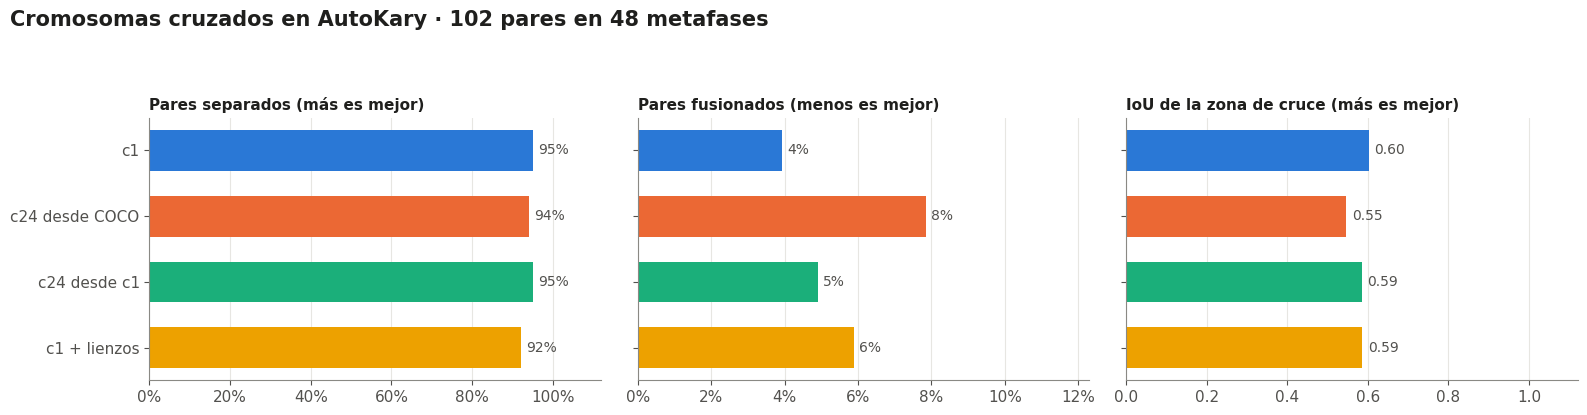

In [10]:
#@title Métrica propia: cromosomas que se cruzan en las metafases de AutoKary { display-mode: "form" }
CROSS_MIN = 0.10  # hay cruce si la zona compartida es al menos el 10 % del cromosoma más pequeño
t0 = time.time()
PARES = {label: [] for label in ('c1', 'c24 desde COCO', 'c24 desde c1', 'c1 + lienzos') if label in MODELS}
n_pairs, metas = 0, set()
for n, p in enumerate(AK, 1):
    img = PILImage.open(p)
    W, H = img.size
    gt = [m for _, m in gt_instances(gt_label_path('chromosome24', stem_of(p)), W, H)]
    gbox = [mask_box(g) for g in gt]
    pairs = [(i, j) for i in range(len(gt)) for j in range(i + 1, len(gt))
             if boxes_touch(gbox[i], gbox[j]) and (gt[i] & gt[j]).sum() >= CROSS_MIN * min(gt[i].sum(), gt[j].sum())]
    if not pairs:
        continue
    n_pairs += len(pairs)
    metas.add(stem_of(p))
    for label in PARES:
        pm = [m for _, m in predict_instances(MODELS[label], p, conf=0.1)]
        pbox = [mask_box(m) for m in pm]
        cand = sorted(((iou_in(gt[g], pm[q], union_box(gbox[g], pbox[q])), g, q) for g in range(len(gt))
                       for q in range(len(pm)) if boxes_touch(gbox[g], pbox[q])), reverse=True)
        best, used = {}, set()
        for v, g, q in cand:
            if v > 0 and g not in best and q not in used:
                best[g] = (q, v)
                used.add(q)
        for i, j in pairs:
            bi, bj = best.get(i), best.get(j)
            box = union_box(gbox[i], gbox[j])
            x0, y0, x1, y1 = box
            gi, gj = gt[i][y0:y1, x0:x1], gt[j][y0:y1, x0:x1]
            fused = any(boxes_touch(b, gbox[i]) and boxes_touch(b, gbox[j]) and
                        mask_iou(m[y0:y1, x0:x1], gi | gj) >= 0.5 and
                        mask_iou(m[y0:y1, x0:x1], gi | gj) > max(mask_iou(m[y0:y1, x0:x1], gi), mask_iou(m[y0:y1, x0:x1], gj))
                        for m, b in zip(pm, pbox))
            p_cross = pm[bi[0]] & pm[bj[0]] if bi and bj else np.zeros_like(gt[i])
            boxes = [gbox[i], gbox[j]] + [pbox[b[0]] for b in (bi, bj) if b]
            PARES[label].append(dict(sep=min(bi[1] if bi else 0, bj[1] if bj else 0) >= 0.5, fused=fused,
                                     cross=iou_in(gt[i] & gt[j], p_cross, union_box(*boxes))))
    if n % 15 == 0 or n == len(AK):
        print(f'  {n}/{len(AK)} metafases', flush=True)

CRUCES_AK = pd.DataFrame([{'Modelo': label, 'Pares separados': np.mean([r['sep'] for r in rs]),
                           'Pares fusionados': np.mean([r['fused'] for r in rs]),
                           'IoU de la zona de cruce': np.mean([r['cross'] for r in rs])}
                          for label, rs in PARES.items() if rs])
print(f'{n_pairs} pares de cromosomas cruzados en {len(metas)} metafases ({time.time() - t0:.0f} s)\n')
display(CRUCES_AK.style.format({'Pares separados': '{:.1%}', 'Pares fusionados': '{:.1%}',
                                'IoU de la zona de cruce': '{:.2f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(16, 0.6 * len(CRUCES_AK) + 1.8), sharey=True)
for ax, (col, title, pct, xmax) in zip(axes, [('Pares separados', 'Pares separados (más es mejor)', True, 1),
                                               ('Pares fusionados', 'Pares fusionados (menos es mejor)', True, None),
                                               ('IoU de la zona de cruce', 'IoU de la zona de cruce (más es mejor)', False, 1)]):
    vals = CRUCES_AK[col].values[::-1]
    names = CRUCES_AK['Modelo'].values[::-1]
    ax.barh(range(len(vals)), vals, 0.62, color=[MODEL_COLOR[m] for m in names])
    for k, v in enumerate(vals):
        ax.annotate(f'{v:.0%}' if pct else f'{v:.2f}', (v, k), xytext=(4, 0), textcoords='offset points', va='center',
                    fontsize=10, color=INK2)
    ax.set_xlim(0, (xmax or max(vals.max() * 1.4, 0.05)) * 1.12)
    ax.set_title(title, fontsize=11)
    if pct:
        ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    ax.grid(axis='x', color=GRID)
    ax.set_axisbelow(True)
axes[0].set_yticks(range(len(names)), names)
fig.suptitle(f'Cromosomas cruzados en AutoKary · {n_pairs} pares en {len(metas)} metafases', x=0.01, ha='left')
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

## Fase 7 · Resumen
**Qué hace:** reúne en una tabla las cifras del modelo propuesto (**c24 desde c1**) calculadas en la fase 6.

In [11]:
#@title Resumen del proceso { display-mode: "form" }
try:
    met = {r['Modelo']: r for r in METRICAS}
    cr = CRUCES_AK.set_index('Modelo')
except NameError:
    raise RuntimeError('Ejecuta antes la fase 6.')
best = met['c24 desde c1']
display(pd.DataFrame([
    {'Fase': '1–2 · Datos', 'Resultado': '3 bases unificadas; contornos a mano + SAM'},
    {'Fase': '3 · Segmentación', 'Resultado': f'mAP50 = {best["Segmentación mAP50"]:.2f} · mAP50-95 = {best["Segmentación mAP50-95"]:.2f}'},
    {'Fase': '4 · Clasificación', 'Resultado': f'mAP50 = {best["Clasificación mAP50"]:.2f} · {ACC:.1%} de cromosomas bien clasificados'},
    {'Fase': '5–6 · Cruces', 'Resultado': f'{cr.loc["c24 desde c1", "Pares separados"]:.0%} de pares separados · '
                                          f'{cr.loc["c24 desde c1", "Pares fusionados"]:.0%} fusionados (metafases de AutoKary)'},
]).style.set_caption('Modelo propuesto: c24 desde c1 · test de AutoKary (75 metafases, contornos a mano)')
  .hide(axis='index'))

Fase,Resultado
1–2 · Datos,3 bases unificadas; contornos a mano + SAM
3 · Segmentación,mAP50 = 0.99 · mAP50-95 = 0.76
4 · Clasificación,mAP50 = 0.96 · 93.7% de cromosomas bien clasificados
5–6 · Cruces,95% de pares separados · 5% fusionados (metafases de AutoKary)


### Conclusiones
1. **Segmentar cromosomas en una metafase ya funciona:** el modelo encuentra casi todos.
2. **La clasificación en 24 clases acierta en la gran mayoría.** Los errores se concentran en cromosomas de tamaño y forma parecidos (13↔14, 19↔22, Y→20).
3. **Los cromosomas que se cruzan se separan en la gran mayoría de los casos.** A tamaño real, el ajuste fino con lienzos es lo que permite separarlos en los recortes.
4. **Entrenar en dos etapas (c1 → c24) vale la pena:** conserva la calidad de segmentación de c1 y añade la clasificación.

**Trabajo a futuro:** usar esta numeración para armar el cariotipo completo, comprobando que haya dos de cada cromosoma.